## Module 2: FSHD Clinical Trial Project Template

Authors: Mona Abou-Assi and Victor Alvarado

## Project Goal:

The goal of this project is to determine which biomarkers and clinical outcome assessments are best at detecting FSHD progression. Using Python, we will analyze real patient data and provide evidence-based proposals for which biomarkers should be used in clinical trials for FSHD treatments. The main objective of this project is to examine the relationship of clinical severity scores and dorsiflexion strength in FSHD patients. We will approach this by looking at three questions: Do higher clinical severity scores correspond with lower dorsiflexion strength? Do clinical severity scores and dorsiflexion strength values change over time? Is there a significant difference in left vs right leg dorsiflexion strength over time? The project will delve into how this research question pertains to the development and evaluation of treatments in a clinical-trial setting. 

## Disease Background: 

**Prevalence & incidence:**
- FSHD is among the most prevalent muscular diseases (also known as myopathy). It is the most common hereditary muscular dystrophy. It affects men, women, and children. The prevalence of FSHD is approximately 1 in 7,500 people. However, the reality is that FSHD is underdiagnosed, and there may be more cases than recorded. Many people carry the gene without being symptomatic. This leads to the genetic prevalence being higher than the clinical prevalence. The incidence is estimated to be 1 in 14,286 births in the world. ("Facts and statistics FSHD", 2014)

**Symptoms**
- FSHD symptoms include weakness in the face, such as not being able to smile or pucker the lips, in the shoulders, making it difficult for patients to lift their arms, in the legs, causing difficulty in lifting the feet, and in the abdomen, leading to curves in the lower spine and affecting posture and balance. Another symptom is chronic pain and inflammation in the lower back, legs, neck, and shoulders. Less common symptoms include joint and spinal changes, respiratory problems, retinal changes, hearing loss, and difficulty swallowing. ("Diseases - FSHD - Signs & Symptoms", 2015) 

**Standard of care treatments (& reimbursement)**
- Medical management of FSHD is characterized by symptoms management, as there is no cure for the disease. Patients may be prescribed NSAIDs for pain management and antidepressant or antiepileptics for chronic pain. Rehabilitative devices are given to patients who need improved posture, including braces and postural supports. Some patients undergo a scapular fixation surgery, which stabilizes the shoulder blade and can lead to improved arm function. A low level of exercise is recommended to support the health and function of the patient. Most standard insurance companies will reimburse patients for their medications, physical therapy, and clinical visits. ("Muscular Dystrophy Association", 2015)

**Disease progression & prognosis**
- FSHD’s progression can begin from adolescence when symptoms may begin to show. However, FSHD’s progression over time for the most part is rather slow. As FSHD progresses symptoms arise primarily as muscle weakness in the face, lower girdle, upper arm, and lower leg. FSHD’s prognosis is that of a manageable disease that allows many affected individuals to live a relatively normal life with management strategies available such as support devices for weakened muscles or physical therapy. Nevertheless, it is estimated that around 20% of FSHD affected individuals end up wheelchairing bound. ("FSHD", 2023)

**Biological mechanisms (anatomy, organ physiology, cell & molecular physiology)**
- The expression of DUX4 is the leading molecular driver behind FSHD. Normally, DUX4 is repressed and remains off. There's two types of FSHD. FSHD type 1 is caused by chromatin relaxation in the D4Z4 repeat region on the 4th Chromosome. (Preston, 2025) The second type of FSHD is caused by epigenetic changes that affect SCHMD1, DNMT3B, and LRIFI genes which similarly lead to de-repression of DUX4. Once DUX4 is expressed in muscle tissue it leads to muscle fiber loss. The DUX4 expression alongside muscle MRIs can be used as biomarkers for FSHD. (Brun, 2026)

**Clinical Trials/next-gen therapies**
- Genetic therapies are being investigated with clinical trials to suppress DUX4. One approach uses siRNA to silence DUX4. The other approach uses epigenetic silencing of the D4Z4 repeat region on the 4th chromosome to reduce DUX4 expression. Lastly, a therapy focusing on using losmapimod found improvements in strengths alongside workspace reachability. However, the placebo group also had the same improvements. (Preston, 2025)

## Data Set:

Describe the FSHD dataset used in your project. Include:

- The subject and visit/timepoint(s) analyzed
- The tibialis anterior MRI data
- The water-image and fat-image files
- The tibialis anterior segmentation mask
- The sampled locations along the muscle
- The meaning and units of the image signals
- The clinical, biomarker, or functional measurements included in the dataset
- The source of the data

Explain how the MRI data and muscle mask were generated or provided for this project. Cite the paper, dataset documentation, or other sources that informed your description.

## MRI Data Analysis Methdology:

### Import Packages and Locate Data

Each library is imported for a different purpose in loading, processing, and visualizing our analysis. The pathlib locates the MRI dataset folder. The NumPy library is what handles MRI image calculations and arrays. The pandas library organizes information about the MRI slices into a table. The matplotlib.pyplot is what allows us to create the graphs and figures. The DATA_DIR call is what specifies the folder which contains the MRI data. The manifest code is what identifies the files and information for each MRI slice.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("FSHD_MRI_data/FSHD_TA_MRI_data_0020_TP1_TP2")
manifest = pd.read_csv(DATA_DIR / "slice_info.csv")
manifest

,subject,timepoint,slice_id,percent_along_muscle,z_index,distance_from_muscle_start_mm,water_file,fat_file,mask_file
0,UW_0020,TP1,1,10,41,24.0,TP1_slice_01_water.npy,TP1_slice_01_fat.npy,TP1_slice_01_mask.npy
1,UW_0020,TP1,2,20,46,44.0,TP1_slice_02_water.npy,TP1_slice_02_fat.npy,TP1_slice_02_mask.npy
2,UW_0020,TP1,3,30,52,68.0,TP1_slice_03_water.npy,TP1_slice_03_fat.npy,TP1_slice_03_mask.npy
3,UW_0020,TP1,4,40,58,92.0,TP1_slice_04_water.npy,TP1_slice_04_fat.npy,TP1_slice_04_mask.npy
4,UW_0020,TP1,5,50,64,116.0,TP1_slice_05_water.npy,TP1_slice_05_fat.npy,TP1_slice_05_mask.npy
5,UW_0020,TP1,6,60,69,136.0,TP1_slice_06_water.npy,TP1_slice_06_fat.npy,TP1_slice_06_mask.npy
6,UW_0020,TP1,7,70,75,160.0,TP1_slice_07_water.npy,TP1_slice_07_fat.npy,TP1_slice_07_mask.npy
7,UW_0020,TP1,8,80,81,184.0,TP1_slice_08_water.npy,TP1_slice_08_fat.npy,TP1_slice_08_mask.npy
8,UW_0020,TP2,1,10,40,24.0,TP2_slice_01_water.npy,TP2_slice_01_fat.npy,TP2_slice_01_mask.npy
9,UW_0020,TP2,2,20,46,48.0,TP2_slice_02_water.npy,TP2_slice_02_fat.npy,TP2_slice_02_mask.npy


### Load One Sample

One of the MRI slices from the first visit, TP1, is selected. In this case, it is in the fourth row (iloc[3]), which corresponds to 40% along the muscle. Three NumPy files get loaded, including the water image that contains MRI water-signal intensities, the fat image that shows fat-signal intensities, and the segmentation mask that shows the tibialis anterior muscle's image pixels. The code loads a segmentation-mask file that corresponds to the water and fat images on the same MRI slice. The code uses a boolean function: if it is true (1), the pixel belongs to the TA muscle, and if it is false (0), it do not belong to the TA muscle. This is important because the code takes out the pixels that include surrounding tissue, and it isolates the pixels with only the TA muscle. 

The output shows three different arrays based on the water image shape, fat image shape, and mask shape. All three arrays have the same dimensions of pixels in the array, so they can all be compared more easily. The third output is the number of pixels that belong to the tibialis anterior muscle. Overall, this data shows us that each image's dimensions are 226 x 224 pixels. The amount of pixels that have the tibialis muscle identified in them is 360 pixels. 


In [3]:
row = manifest[manifest["timepoint"] == "TP1"].iloc[3]  # representative mid-muscle slice

water = np.load(DATA_DIR / row["water_file"])
fat = np.load(DATA_DIR / row["fat_file"])
mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)

print("Water image shape:", water.shape)
print("Fat image shape:", fat.shape)
print("Mask shape:", mask.shape)
print("Number of muscle pixels:", mask.sum())

Water image shape: (266, 224)
Fat image shape: (266, 224)
Mask shape: (266, 224)
Number of muscle pixels: 360


### Calculate Fat Fraction

The fat fraction is a measure of the proportion of fat in the combined water and fat signals from the MRI image. A higher percentage means there is more fat in the pixel. The formula for calculating fat fraction is: 

$$ \text{Fat Fraction} = \frac{\text{fat}}{\text{fat + water}}\cdot 100\%$$

The code divides the fat signals by the denominator, which is the water plus fat. The code ensures that the denominator is not equal to zero to avoid dividing by zero. The code creates a NumPy array for the full fat fraction, which is the TA muscle and the surrounding tissue for the first analysis. Another array created is the masked fat fraction, which is the fat fraction for only the regions with tibialis anterior muscle.  

The results show that the mean fat fraction for the whole supplied image region is 48.6%. The mean fat fraction for the muscle only is 29.9%. The TA muscle value is more relevant to this study because it focuses solely on the muscle being evaluated. 


In [4]:
denominator = water + fat
valid_pixels = denominator > 0

fat_fraction = np.divide(
    fat,
    denominator,
    out=np.zeros_like(fat, dtype=float),
    where=valid_pixels
) * 100

# Keep the whole supplied image region for the first analysis.
fat_fraction_full = fat_fraction.copy()

# Then apply the TA mask for the muscle-specific analysis.
fat_fraction_masked = fat_fraction.copy()
fat_fraction_masked[~mask] = np.nan

whole_image_values = fat_fraction_full[valid_pixels]
muscle_values = fat_fraction_masked[~np.isnan(fat_fraction_masked)]

print(f"Whole supplied image region — mean: {np.mean(whole_image_values):.1f}%")
print(f"Whole supplied image region — minimum: {np.min(whole_image_values):.1f}%")
print(f"Whole supplied image region — maximum: {np.max(whole_image_values):.1f}%")
print()
print(f"TA muscle only — mean: {np.mean(muscle_values):.1f}%")
print(f"TA muscle only — minimum: {np.min(muscle_values):.1f}%")
print(f"TA muscle only — maximum: {np.max(muscle_values):.1f}%")

Whole supplied image region — mean: 48.6%
Whole supplied image region — minimum: 0.0%
Whole supplied image region — maximum: 100.0%

TA muscle only — mean: 29.9%
TA muscle only — minimum: 0.5%
TA muscle only — maximum: 90.7%


### Visualize the Images, the Mask, and Fat-Fraction Map

The code generates four different images obtained from the same MRI slice. The first image combines the water and TA mask. The white highlighting shows the water signal and the red outline shows the TA muscle. The second image is the fat image and TA mask. The white highlighting shows the fat signal and the red outline shows the TA muscle. The third image shows the fat fraction in the whole image, including the TA muscle and its surrounding tissue. The fourth image shows the fat fraction solely in the TA muscle. The first two images are important because they allow us to visualize the fat and water content and locate the TA muscle in the MRI slice. The third and fourth images are important because it allows us to visualize the fat fraction in the whole slice and in solely the TA muscle. The fourth image is especially important because it is what we will perform the main analysis on. This image shows the fat fraction percentage and a corresponding color scheme to label each pixel.

The code does this by first creating the figure and then multiple panels where the MRI images appear. imshow() displays the MRI data arrays into an image. contour() is what allows the TA muscle to be outlined in red. Then, cmap tells Matplotlib to display certain colors based on the numerical values stored. cmap = "gray" is used for the water and fat images. The shades of gray represent MRI signal intensities. For the fat fraction color map, vmin and vmax are used to set the scale for fat fraction, and the colorbar corresponds with this scale. plt.show() is what shows the image. The arrap  

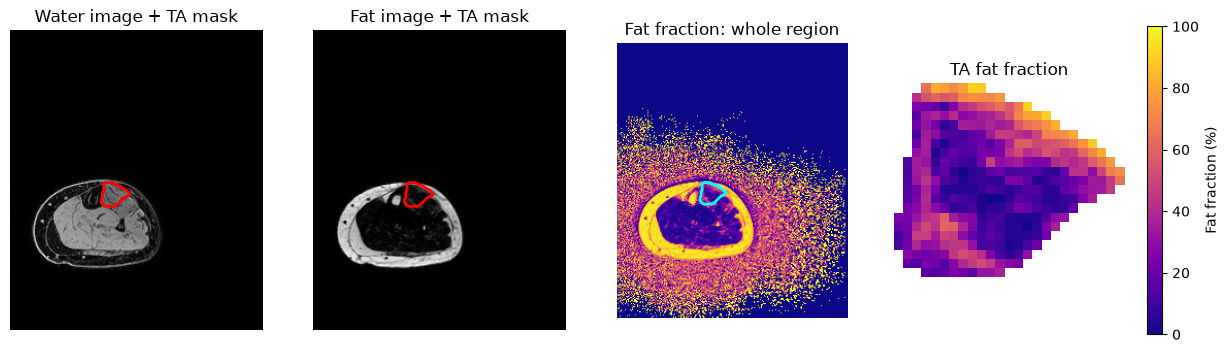

In [5]:
# Find the bounding box of the TA mask
y_pixels, x_pixels = np.where(mask)

y0, y1 = y_pixels.min(), y_pixels.max() + 1
x0, x1 = x_pixels.min(), x_pixels.max() + 1

# Crop the TA-specific fat-fraction map
fat_fraction_TA = fat_fraction_masked[y0:y1, x0:x1]

fig, axes = plt.subplots(1, 4, figsize=(15, 4))

# Water image with TA mask outline
axes[0].imshow(water, cmap="gray")
axes[0].contour(mask, levels=[0.5], colors="red", linewidths=2)
axes[0].set_title("Water image + TA mask")

# Fat image with TA mask outline
axes[1].imshow(fat, cmap="gray")
axes[1].contour(mask, levels=[0.5], colors="red", linewidths=2)
axes[1].set_title("Fat image + TA mask")

# Fat fraction for the whole supplied image region
whole_image = axes[2].imshow(
    fat_fraction_full,
    cmap="plasma",
    vmin=0,
    vmax=100
)
axes[2].contour(mask, levels=[0.5], colors="cyan", linewidths=2)
axes[2].set_title("Fat fraction: whole region")

# Zoomed-in fat fraction for the TA only
ta_image = axes[3].imshow(
    fat_fraction_TA,
    cmap="plasma",
    vmin=0,
    vmax=100
)
axes[3].set_title("TA fat fraction")

for ax in axes:
    ax.axis("off")

# Both fat-fraction plots use the same 0–100% scale
fig.colorbar(
    ta_image,
    ax=axes[2:],
    fraction=0.046,
    pad=0.04,
    label="Fat fraction (%)"
)

plt.show()

### Visualize the Fat-Fraction Distribution

This histograms displays the distribution of fat-fraction values in the whole supplied region and the TA muscle only, respectively.

This does this by retrieving whole_image_values, which contains the fat-fraction values from the whole image (calculated in the fat fraction section). The code plt.figure creates the figure and plt.hist specifically creates a histogram. The code bins=30 divides the data set into 30 different intervals, which makes up the x-axis of the graph (this is the same for both histograms). The bar heights represent the number of pixels that have that percentage of fat fraction on the graph. The rest of the code is the general formatting of the histogram. The same process is completed for the second histogram, but with the fat-fraction values for the TA muscle only. The TA-specific image is cropped by np.where(mask) finding the positions of the TA pixels in the whole MRI image. Array slicing is used to crop the image to only the TA muscle. Note the difference in values on the y-axis, as there are far less pixels being considered in the TA muscle only rather than the whole MRI image. 

This is important because it visualizes the data into an organized format where we can see the fat-fraction distribution for the whole supplied region and the TA muscle only. 

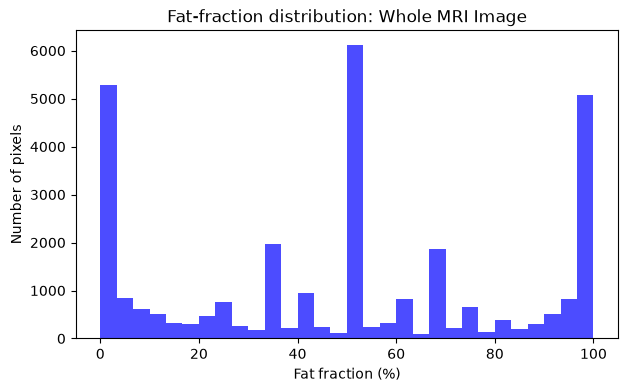

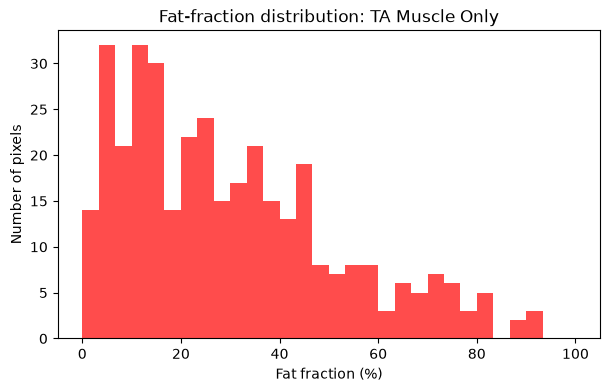

In [11]:
# Use the same bin boundaries for both datasets

# Use the same bins for both histograms
bins = np.linspace(0, 100, 31)

# Histogram 1: Whole MRI image
plt.figure(figsize=(7, 4))
plt.hist(whole_image_values, bins=bins, color="blue", alpha=0.7)
plt.xlabel("Fat fraction (%)")
plt.ylabel("Number of pixels")
plt.title("Fat-fraction distribution: Whole MRI Image")
plt.show()

# Histogram 2: TA muscle only
plt.figure(figsize=(7, 4))
plt.hist(muscle_values, bins=bins, color="red", alpha=0.7)
plt.xlabel("Fat fraction (%)")
plt.ylabel("Number of pixels")
plt.title("Fat-fraction distribution: TA Muscle Only")
plt.show()


### Repeat the Analysis for Every Sampled Location in One Visit

The function below packages the calculation so it can be reused for every row in the selected visit. This shows how the code generates the summary measurements. The def caculate_fat_fraction(water, fat, mask) defines a reusable Python function that inputs the water image, fat image, and segmentation mask, and returns an array that contains the fat-fraction percentages of the TA muscle pixels. The analysis_timepoint = "TP1" code picks a specific visit to be analyzed, TP1. Then an empty list is created for the results. A for loops is created that analyzes each MRI slice in TP1, and for each slice the water, fat, and mask files are loaded. The NumPy library is used to calculate the average fat-fraction percentage in TA muscle, middle fat-fraction percentage, and standard deviation. The code results.append() adds the measurements and information for each MRI slice in into the empty list. Then the list of measurements are converted into a DataFrame named results_df. Each row is one MRI location. 



In [ ]:
def calculate_fat_fraction(water, fat, mask): #Defines a reusable Python function.
    """Return a masked fat-fraction image in percent."""
    denominator = water + fat
    result = np.divide(
        fat,
        denominator,
        out=np.zeros_like(fat, dtype=float),
        where=denominator > 0
    ) * 100
    result[~mask] = np.nan
    return result

analysis_timepoint = "TP1"  # analyze one visit at a time
analysis_manifest = manifest[manifest["timepoint"] == analysis_timepoint]
results = []

for _, row in analysis_manifest.iterrows():
    water = np.load(DATA_DIR / row["water_file"])
    fat = np.load(DATA_DIR / row["fat_file"])
    mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)
    ff = calculate_fat_fraction(water, fat, mask)

    results.append({
        "subject": row["subject"],
        "timepoint": row["timepoint"],
        "slice_id": row["slice_id"],
        "percent_along_muscle": row["percent_along_muscle"],
        "distance_from_muscle_start_mm": row["distance_from_muscle_start_mm"],
        "mean_fat_fraction_percent": np.nanmean(ff),
        "median_fat_fraction_percent": np.nanmedian(ff),
        "std_fat_fraction_percent": np.nanstd(ff),
        "n_muscle_pixels": int(mask.sum()),
    })

results_df = pd.DataFrame(results)
results_df

,subject,timepoint,slice_id,percent_along_muscle,distance_from_muscle_start_mm,mean_fat_fraction_percent,median_fat_fraction_percent,std_fat_fraction_percent,n_muscle_pixels
0,UW_0020,TP1,1,10,24.0,83.924382,88.827837,13.272006,61
1,UW_0020,TP1,2,20,44.0,82.706905,86.651582,12.433905,115
2,UW_0020,TP1,3,30,68.0,58.498513,61.821705,22.878862,231
3,UW_0020,TP1,4,40,92.0,29.931733,25.369646,21.584495,360
4,UW_0020,TP1,5,50,116.0,20.866866,14.553991,20.060150,421
5,UW_0020,TP1,6,60,136.0,16.758732,9.049959,19.665424,440
6,UW_0020,TP1,7,70,160.0,17.511838,8.962264,20.456168,388
7,UW_0020,TP1,8,80,184.0,27.873337,22.685185,22.625359,263


### Extension: Compare Fat Fraction Profiles Across Two Visits

This extension repeats the same calculation for TP1 and TP2. Use physical distance on the x-axis. The percent location is useful as a reference, but it is not a substitute for the measured spacing.

First, def summarize_visit creates a resuable function that takes one visit at a time and analyzes it. The input is the timepoint (i.e. TP1, TP2). Then, visit_manifest filters this data to sort out the slices from the specific visit. Each slice's fat fraction average is caluclated, adn the timepoint, slide ID, percentage along the muscle, and distance are recorded. Then, the visit's measurments are organized into a DataFrame. The TP1 and TP2 DataFrames are combined into a table, profiles_df. The TP1 and TP2 groups are separated with the groupby("timepoint") code. Then the measurement values are sorted by location along the muscle, which is helpful in creating the plotted points in the correct spatial order. plt.plot() plots the distance from start (mm) against the mean TA fat fraction (%). The rest of the code is the general formatting for the graph.

The output is a graph with two lines, one representing TP1 and the other representing TP2. The graph represents the mean TA fat fraction percentage at different distances from the muscle start. 

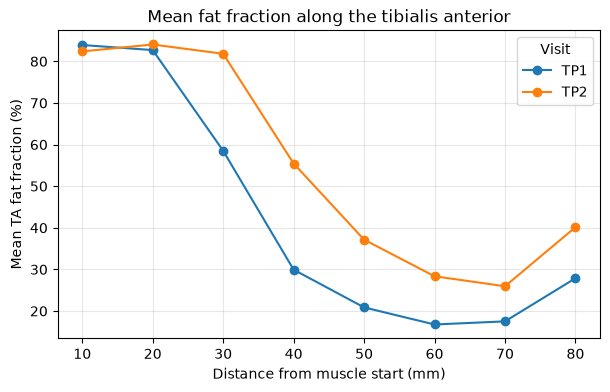

In [13]:
def summarize_visit(timepoint):
    visit_results = []
    visit_manifest = manifest[manifest["timepoint"] == timepoint]

    for _, row in visit_manifest.iterrows():
        water = np.load(DATA_DIR / row["water_file"])
        fat = np.load(DATA_DIR / row["fat_file"])
        mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)
        ff = calculate_fat_fraction(water, fat, mask)

        visit_results.append({
            "timepoint": timepoint,
            "slice_id": row["slice_id"],
            "percent_along_muscle": row["percent_along_muscle"],
            "distance_from_muscle_start_mm": row["distance_from_muscle_start_mm"],
            "mean_fat_fraction_percent": np.nanmean(ff),
        })

    return pd.DataFrame(visit_results)

profiles_df = pd.concat(
    [summarize_visit("TP1"), summarize_visit("TP2")],
    ignore_index=True
)

plt.figure(figsize=(7, 4))
for timepoint, group in profiles_df.groupby("timepoint"):
    group = group.sort_values("distance_from_muscle_start_mm")
    plt.plot(
        group["percent_along_muscle"],
        group["mean_fat_fraction_percent"],
        marker="o",
        label=timepoint
    )
plt.xlabel("Distance from muscle start (mm)")
plt.ylabel("Mean TA fat fraction (%)")
plt.title("Mean fat fraction along the tibialis anterior")
plt.legend(title="Visit")
plt.grid(True, alpha=0.3)
plt.show()

### Save a Reusable Summary File

The calculated statistics are stored by first specifying the file location and name where the data is saved. The file is saved and exported in a csv file. The code prints a filename for the saved data.

It is important for the code to save this data because the results can be analyzed without having to rerun all this code. These measurements can also be imported into another coding platform and used. 

In [14]:
output_file = Path("TA_fat_fraction_summary.csv")
results_df.to_csv(output_file, index=False)
print(f"Saved {output_file}")

Saved TA_fat_fraction_summary.csv


### Longitudinal Comparison

If you run the analysis once for each visit, compare TP1 and TP2 at approximately the same percent location along the muscle. A change in MRI fat fraction may indicate a change in muscle composition, but it is not automatically evidence of improved or worsened patient function.

The code selects profiles_df if it exists, and if it does not exist results_df is used. The data is sorted so that TP1 and TP2 each have their own columns. Then, subtraction occurs between TP1 mean fat fraction and TP2 mean fat fraction. This difference is stored in "change_TP2_minus_TP1". The final table displays TP1, TP2 and the calculated difference for each location. The else statement prints a message that the users should run the two-visit extension if the required data is not available.

In [15]:
comparison_source = profiles_df if "profiles_df" in globals() else results_df
comparison = comparison_source.pivot(
    index="percent_along_muscle",
    columns="timepoint",
    values="mean_fat_fraction_percent"
)

if {"TP1", "TP2"}.issubset(comparison.columns):
    comparison["change_TP2_minus_TP1"] = comparison["TP2"] - comparison["TP1"]
    display(comparison)
else:
    print("Run the optional two-visit extension before making a longitudinal comparison.")

timepoint,TP1,TP2,change_TP2_minus_TP1
percent_along_muscle,,,
10,83.924382,82.390320,-1.534061
20,82.706905,84.049364,1.342458
30,58.498513,81.815108,23.316595
40,29.931733,55.449853,25.518120
50,20.866866,37.146636,16.279770
60,16.758732,28.351047,11.592316
70,17.511838,25.945668,8.433830
80,27.873337,40.143158,12.269821


## Interpolation Analysis:

Explain how interpolation was used to estimate fat fraction or another measurement at a location between sampled points along the tibialis anterior.

Include:

- The variable used to define location along the muscle, such as distance in millimeters or percentage of muscle length
- The sampled locations used as inputs to the interpolation
- The interpolation method and Python code used
- A plot showing the measured values and the interpolated estimate(s)
- Why interpolation is an estimate rather than a new measurement
- The assumptions made about how the measurement changes between sampled locations
- Whether the estimate is within the range of sampled data or represents extrapolation
- Any limitations or sources of uncertainty in the interpolated result

### Import Packages and Locate Data ###

Imports packages and locates the data

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

### Linear Interpolation - the Math ###

Two known points `(x1, y1)` and `(x2, y2)`. We want the coefficients `a1` (intercept) and `a2` (slope) of `f(x) = a1 + a2*x`, by solving `Y = Z · A`.

This section provides the mathematical method of linear interpolation. Instead of using actual FSHD patient data, however, it uses sample numbers. 

The example plot demonstrates how to visualite interpolation as an example, not a final plot with actual FSHD results.

In [14]:
# Known points
x1, x2 = 1, 3
y1, y2 = 1, 3

# Z and Y matrices
Z = np.array([[1, x1],
              [1, x2]])
Y = np.array([y1, y2])

# Solve for A = [a1, a2]
A = np.linalg.solve(Z, Y)
print("A =", A)

A = [0. 1.]


In [16]:
# Use the coefficients to estimate y at a new x
a1, a2 = A
x_value = 2
y_value = a1 + a2 * x_value
print(f"At x = {x_value}, y = {y_value}")

At x = 2, y = 2.0


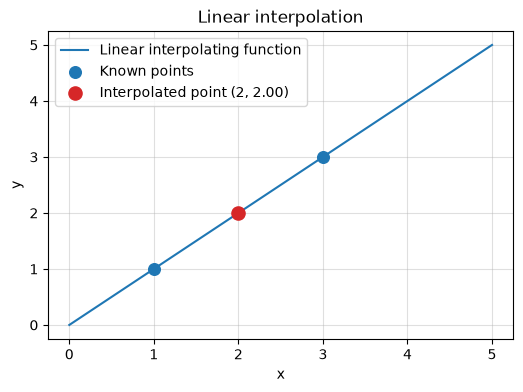

In [18]:
# Plot the line and the interpolated point
x_line = np.linspace(0, 5, 100)
y_line = a1 + a2 * x_line

plt.figure(figsize=(6, 4))
plt.plot(x_line, y_line, label="Linear interpolating function")
plt.scatter([x1, x2], [y1, y2], color="tab:blue", s=70, zorder=4, label="Known points")
plt.scatter([x_value], [y_value], color="tab:red", s=90, zorder=5,
            label=f"Interpolated point ({x_value}, {y_value:.2f})")
plt.title("Linear interpolation")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.4)
plt.legend()
plt.show()

### Quadratic Interpolation - the Math ###

Three known points. We want `a1, a2, a3` of `f(x) = a1 + a2*x + a3*x²`, again by solving `Y = Z · A` — this time `Z` has three columns: `[1, xi, xi²]`.

This section provides the mathematical method of quadratic interpolation. Instead of using actual FSHD patient data, however, it uses sample numbers. The example plot demonstrates how to visualite quadratic interpolation. 

In [20]:
# Known points
x1, x2, x3 = 1, 3, 5
y1, y2, y3 = 1, 3, 2

Z = np.array([[1, x1, x1**2],
              [1, x2, x2**2],
              [1, x3, x3**2]])
Y = np.array([y1, y2, y3])

A = np.linalg.solve(Z, Y)
print("A =", A)


A = [-1.125  2.5   -0.375]


In [21]:
a1, a2, a3 = A
x_value = 4
y_value = a1 + a2 * x_value + a3 * x_value**2
print(f"At x = {x_value}, y = {y_value}")


At x = 4, y = 2.875


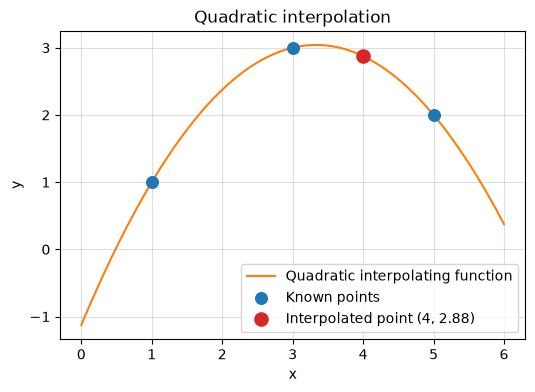

In [22]:
x_curve = np.linspace(0, 6, 200)
y_curve = a1 + a2 * x_curve + a3 * x_curve**2

plt.figure(figsize=(6, 4))
plt.plot(x_curve, y_curve, color="tab:orange", label="Quadratic interpolating function")
plt.scatter([x1, x2, x3], [y1, y2, y3], color="tab:blue", s=70, zorder=4, label="Known points")
plt.scatter([x_value], [y_value], color="tab:red", s=90, zorder=5,
            label=f"Interpolated point ({x_value}, {y_value:.2f})")
plt.title("Quadratic interpolation")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.4)
plt.legend()
plt.show()

### Loading Our Data ###

`Module2_FSHD_Dataset.csv` has one row per subject, with separate columns for each visit (baseline, Year 1, Year 2) rather than one row per visit. Put the CSV in the same folder as this notebook.

The data uses the FSHD patient dataset to examine the relationship between clinical severity scores and dorsiflexion strenght. The measurements from each visit allows us to analyze the disease progression and compare the sensitivity of the two clinical measurements.

The two variables being used for this analysis are clinical severity score and dorsiflexion strength. The clinical severity score is a measure of the patient's muscles and physical abilties that are affected by FSHD. A higher score indicates lower physical ability. Dorsiflexion is the movement of lifting your foot upwards towards your shin. A lower dorsiflexion strenght indicates weaker muscles, mostly the tibialis anterior muscle.  

In [23]:
df = pd.read_csv("/Users/monaabouassi/Desktop/FALL 26/BME 2315/BME 2315 Module 2/MODULE2/Untitled/Module2_FSHD_Dataset.csv")
print(df.shape)
df.head()

(34, 46)


,subject_id,sex,age_baseline,d4z4,dux4_signature_baseline_R,dux4_signature_baseline_L,lag_months_baseline,lag_months_y1,lag_months_y2,ff_baseline_R,...,wr_10_y2,ascend_4_baseline,ascend_4_y1,ascend_4_y2,descend_4_baseline,descend_4_y1,descend_4_y2,clinical_severity_score_baseline,clinical_severity_score_y1,clinical_severity_score_y2
0,1-0019,M,47.06,4,0.060426,0.052982,0,11.74,22.78,5.977253,...,2.52,1.89,2.13,1.63,1.76,1.84,1.64,2,3.0,3.0
1,1-0020,F,24.28,4,0.029324,0.085611,0,16.80,NaN,10.825636,...,NaN,2.15,2.50,NaN,1.89,2.07,NaN,4,6.0,NaN
2,1-0021,M,36.42,6,0.056946,0.264634,0,12.20,23.51,3.346368,...,2.65,1.40,1.60,1.76,1.52,1.40,1.39,0,0.0,1.0
3,1-0022,F,59.43,2,0.877067,0.217580,0,13.35,24.82,5.476659,...,4.44,1.97,2.15,1.97,1.87,2.25,2.27,3,3.0,2.0
4,1-0023,M,63.92,5,2.694204,2.876636,0,11.97,24.39,26.596680,...,3.59,2.32,2.26,2.20,2.00,2.13,2.15,4,4.0,6.0


In [24]:
# Check for missing visits -- not every subject has a Year 1 and/or Year 2 visit
print("Subjects:", len(df))
print("Have a Year 1 visit:", df['lag_months_y1'].notna().sum())
print("Have a Year 2 visit:", df['lag_months_y2'].notna().sum())

Subjects: 34
Have a Year 1 visit: 32
Have a Year 2 visit: 27


In [25]:
print(df.columns.tolist()) # prints the name of each column

['subject_id', 'sex', 'age_baseline', 'd4z4', 'dux4_signature_baseline_R', 'dux4_signature_baseline_L', 'lag_months_baseline', 'lag_months_y1', 'lag_months_y2', 'ff_baseline_R', 'ff_y1_R', 'ff_y2_R', 'ff_baseline_L', 'ff_y1_L', 'ff_y2_L', 'fvar_baseline_R', 'fvar_y1_R', 'fvar_y2_R', 'fvar_baseline_L', 'fvar_y1_L', 'fvar_y2_L', 'stir_quant_baseline_R', 'stir_quant_y1_R', 'stir_quant_baseline_L', 'stir_quant_y1_L', 'dorsiflexion_qmt_R_baseline', 'dorsiflexion_qmt_R_y1', 'dorsiflexion_qmt_R_y2', 'dorsiflexion_qmt_L_baseline', 'dorsiflexion_qmt_L_y1', 'dorsiflexion_qmt_L_y2', 'tug_time_baseline', 'tug_time_y1', 'tug_time_y2', 'wr_10_baseline', 'wr_10_y1', 'wr_10_y2', 'ascend_4_baseline', 'ascend_4_y1', 'ascend_4_y2', 'descend_4_baseline', 'descend_4_y1', 'descend_4_y2', 'clinical_severity_score_baseline', 'clinical_severity_score_y1', 'clinical_severity_score_y2']


### Choosing a fair common time point ###

If we just picked month 12 and month 24 for everyone, some subjects' visits never reach that far — estimating for them would mean **extrapolating** (which we want to avoid), not interpolating. Instead, we use the earliest "last visit" time shared by the whole group — every subject's own data reaches at least that far, so everyone can be purely interpolated, never extrapolated.

We will use interpolation to estimate dorsiflexion strength and clinical severity scores at the standardized follow-up times, allowing us to compare changes across patients whose visits occurred at different months. The independent variable being used is lag_months, which represents the months passed since the patient's baseline visit.

Our project investigates the relationship between clinical severity scores and dorsiflexion strength, how these measurements change over time, and whether dorsiflexion strength differs between the left and right legs. It is important to pick the correct meaasurements and techniques for this analysis.

In [27]:
T1 = df['lag_months_y1'].min()   # earliest Year-1 visit across all subjects
T2 = df['lag_months_y2'].min()   # earliest Year-2 visit across all subjects
print(f"T1 = {T1:.2f} months")
print(f"T2 = {T2:.2f} months")

print("Patients with Year 1 timing data:",
      df['lag_months_y1'].notna().sum())

print("Patients with Year 2 timing data:",
      df['lag_months_y2'].notna().sum())

print("Patients with all three visit times:",
      df[['lag_months_baseline', 'lag_months_y1',
          'lag_months_y2']].notna().all(axis=1).sum())

T1 = 11.15 months
T2 = 22.13 months
Patients with Year 1 timing data: 32
Patients with Year 2 timing data: 27
Patients with all three visit times: 26


### Worked example — Subject 13-0004 ###

Our project examines the relationship between clinical severity scores and dorsiflexion strength in FSHD patients.

To investigate this question, we will examine the clinical severity scores and dorsiflexion strength measurements of Subject 13-0004 at baseline, Year 1, and Year 2. We will use linear and quadratic interpolation to estimate these measurements at common time points (T1 = 11.15 months and T2 = 22.13 months).

The left and right dorsiflextion strength will be analyzes separately, given that FSHD can affect the left and right sides differently.

In [30]:

# Select Subject 13-0004
row = df.loc[df['subject_id'] == '13-0004'].iloc[0]

# Time of each visit (months since baseline)
lag_months = np.array([
    row['lag_months_baseline'],
    row['lag_months_y1'],
    row['lag_months_y2']
])

# Clinical severity scores
severity_values = np.array([
    row['clinical_severity_score_baseline'],
    row['clinical_severity_score_y1'],
    row['clinical_severity_score_y2']
])

# Right dorsiflexion strength
dorsiflexion_R = np.array([
    row['dorsiflexion_qmt_R_baseline'],
    row['dorsiflexion_qmt_R_y1'],
    row['dorsiflexion_qmt_R_y2']
])

# Left dorsiflexion strength
dorsiflexion_L = np.array([
    row['dorsiflexion_qmt_L_baseline'],
    row['dorsiflexion_qmt_L_y1'],
    row['dorsiflexion_qmt_L_y2']
])

print("Time Since Baseline for Each Visit (Months)", ", ".join(map(str, lag_months)))
print("Clinical severity scores:", ", ".join(map(str, severity_values)))
print("Right dorsiflexion:", ", ".join(map(str, dorsiflexion_R)))
print("Left dorsiflexion:", ", ".join(map(str, dorsiflexion_L)))

Time Since Baseline for Each Visit (Months) 0.0, 12.26, 36.89
Clinical severity scores: 5.0, 7.0, 6.0
Right dorsiflexion: 9.6, 11.1, 12.8
Left dorsiflexion: 17.3, 14.9, 18.0


### Linear Interpolation at T1, by hand (using baseline and Year 1) ###

We will estimate the clinical severity scores and dorsiflexion strength at T1 = 11.15 months after baseline using linear interpolation. Linear interpolation works by taking two known measurements and assuming a constant slope between them. 

The two known measurements in this case are the patient's baseline and Year 1 measurements. Specifically for Subject 13-004, the the baseline visit occurred at 0 moths and the Year 1 visit occurred at 12.26 months. This is beneficial because T1 = 11.15 falls in between those two numbers.


Using these for interpolation allows us to compare the measurements at a common time point, regardless of having the patients' visits be at different times.

In [31]:
# Use baseline and Year 1 visit times
x1, x2 = lag_months[0], lag_months[1]

# Perform linear interpolation for each measurement
for name, values in [
    ("Clinical Severity Score", severity_values),
    ("Right Dorsiflexion", dorsiflexion_R),
    ("Left Dorsiflexion", dorsiflexion_L)
]:
    y1, y2 = values[0], values[1]

    # Set up matrices
    Z = np.array([[1, x1], [1, x2]])
    Y = np.array([y1, y2])

    # Solve for the coefficients
    A = np.linalg.solve(Z, Y)
    a1, a2 = A

    # Estimate the measurement at T1
    estimate_T1 = a1 + a2 * T1

    print(f"{name} at T1 ({T1:.2f} months): {estimate_T1:.2f}")

Clinical Severity Score at T1 (11.15 months): 6.82
Right Dorsiflexion at T1 (11.15 months): 10.96
Left Dorsiflexion at T1 (11.15 months): 15.12


### Quadratic interpolation at T2, by hand (using all three visits) ###

Now we are estimating the clinical severity scores and dorsiflexion strength at T2 = 22.13 months after baseline using quadratic interpolation. Quadratic interpolation requires three points rather than only two points like linear interpolation. In this case, they are baseline, Year 1, and Year 2. 

Quadratic interpolation has the equation $f(x) = a_1 + a_2x + a_3x^2$. 

We will apply this method separately to clinical severity scores, right dorsiflexion strength, and left dorsiflexion strength. Our assumptions is that the measurements follow a quadratic pattern between the actual values of the observed visits. 



In [32]:
# Perform quadratic interpolation using all three visits
for name, values in [
    ("Clinical Severity Score", severity_values),
    ("Right Dorsiflexion", dorsiflexion_R),
    ("Left Dorsiflexion", dorsiflexion_L)
]:
    # Set up matrices using all three visit times
    Z = np.array([[1, x, x**2] for x in lag_months])
    Y = values

    # Solve for the coefficients
    A = np.linalg.solve(Z, Y)
    a1, a2, a3 = A

    # Estimate the measurement at T2
    estimate_T2 = a1 + a2 * T2 + a3 * T2**2

    print(f"{name} at T2 ({T2:.2f} months): {estimate_T2:.2f}")

Clinical Severity Score at T2 (22.13 months): 7.40
Right Dorsiflexion at T2 (22.13 months): 11.99
Left Dorsiflexion at T2 (22.13 months): 14.87


### Same Estimates, the shortcut way with `interp1d` ###

Interp1d is a program from SciPy that performs the same interpolation calculations, but does not have to manually solve the matrices. These results will be checked against our former interpolation calculations. 

After obtaining the results, we verified that they align with the interpolation results from the previous "by hand" calculations. 

In [33]:
# Use interp1d to calculate the estimates for each measurement
for name, values in [
    ("Clinical Severity Score", severity_values),
    ("Right Dorsiflexion", dorsiflexion_R),
    ("Left Dorsiflexion", dorsiflexion_L)
]:
    # Linear interpolation using baseline and Year 1
    f_linear = interp1d(lag_months[:2], values[:2], kind='linear')

    # Quadratic interpolation using all three visits
    f_quadratic = interp1d(lag_months, values, kind='quadratic')

    # Calculate estimates at T1 and T2
    estimate_T1 = float(f_linear(T1))
    estimate_T2 = float(f_quadratic(T2))

    print(f"{name}:")
    print(f"  Linear estimate at T1 ({T1:.2f} months): {estimate_T1:.2f}")
    print(f"  Quadratic estimate at T2 ({T2:.2f} months): {estimate_T2:.2f}")
    print()

Clinical Severity Score:
  Linear estimate at T1 (11.15 months): 6.82
  Quadratic estimate at T2 (22.13 months): 7.40

Right Dorsiflexion:
  Linear estimate at T1 (11.15 months): 10.96
  Quadratic estimate at T2 (22.13 months): 11.99

Left Dorsiflexion:
  Linear estimate at T1 (11.15 months): 15.12
  Quadratic estimate at T2 (22.13 months): 14.87



### Plot: Both Known Visits and Both Estimates ###

This graph is plotting the clinical severity scores, right dorsiflexion, and left dorsiflexion over time. The original measurements are from the patients' baseline, Year 1, and Year 2 visits. The interpolated values are from T1 = 11.15 months and T2 = 22.13 months. The data is going to generate three separate plots to make it easier to visualize each measurements.

These graphs are using both linear and quadratic interpolation. Our assumptions are that the values follow a linear or quadratic pattern between the actual observed visits.


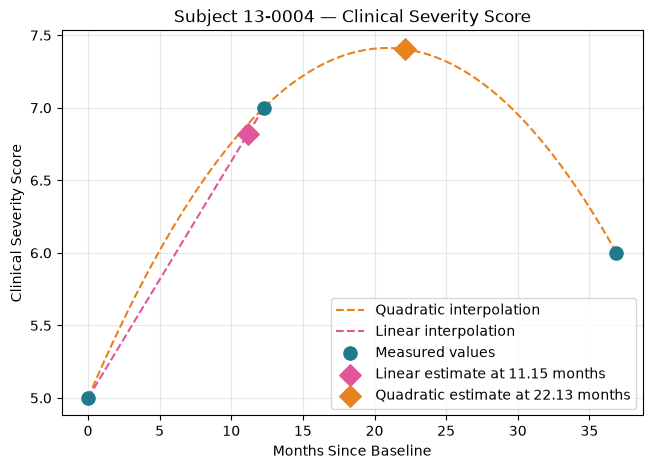

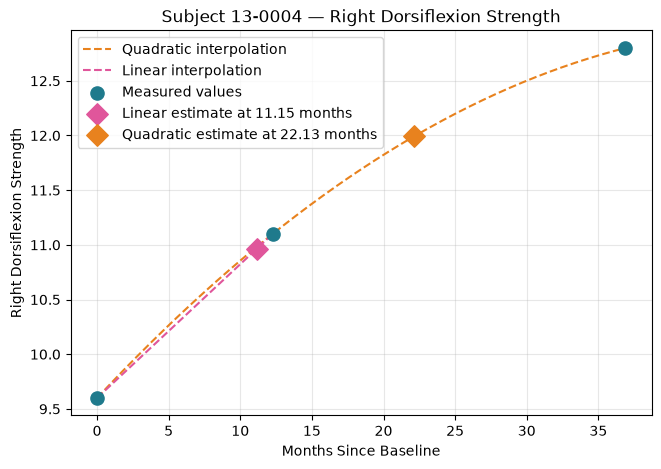

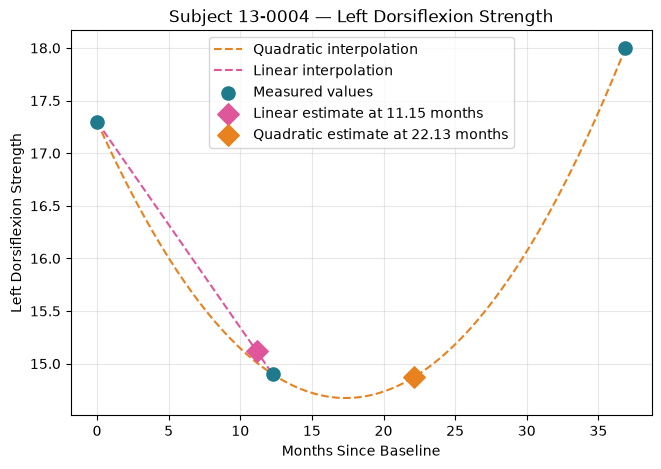

In [34]:
# Colors for the plots
TEAL = "#1f7a8c"
PINK = "#e0569b"
ORANGE = "#e8821e"

# Plot each measurement separately
for name, values in [
    ("Clinical Severity Score", severity_values),
    ("Right Dorsiflexion Strength", dorsiflexion_R),
    ("Left Dorsiflexion Strength", dorsiflexion_L)
]:
    # Create interpolation functions for this measurement
    f_linear = interp1d(lag_months[:2], values[:2], kind="linear")
    f_quadratic = interp1d(lag_months, values, kind="quadratic")

    # Calculate estimates
    estimate_T1 = float(f_linear(T1))
    estimate_T2 = float(f_quadratic(T2))

    # Create curves
    x_linear = np.linspace(lag_months[0], lag_months[1], 100)
    x_curve = np.linspace(lag_months[0], lag_months[-1], 200)

    plt.figure(figsize=(7.5, 5))

    # Interpolation curves
    plt.plot(x_curve, f_quadratic(x_curve),
             color=ORANGE, linestyle="--",
             label="Quadratic interpolation")

    plt.plot(x_linear, f_linear(x_linear),
             color=PINK, linestyle="--",
             label="Linear interpolation")

    # Original measured values
    plt.scatter(lag_months, values, color=TEAL,
                s=90, zorder=4, label="Measured values")

    # Interpolated estimates
    plt.scatter(T1, estimate_T1, color=PINK,
                marker="D", s=120, zorder=5,
                label=f"Linear estimate at {T1:.2f} months")

    plt.scatter(T2, estimate_T2, color=ORANGE,
                marker="D", s=120, zorder=5,
                label=f"Quadratic estimate at {T2:.2f} months")

    plt.title(f"Subject 13-0004 — {name}")
    plt.xlabel("Months Since Baseline")
    plt.ylabel(name)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

### Apply this to Every Subject ###

Here we are extending the interpolation methods to every subject in the data set. The data will estimate the interpolated values for the clinical severity score, right dorsiflexion, and left dorsiflexion. We must account for the patients with missing measurements, which will be addressed here. These results will be saved to a csv file so they can be accessed whenever needed. 

This code contains a for loop to iterate through each row of the data set and find our desired measurements.

We are using the interp1d() method to apply linaer and quadratic interpolation to the data. We are addressing limitations and uncertainties by handling missing data points rather than creating false measurements for patients without all baseline, Year 1, and Year 2 visits.

In [37]:
results = []

for idx, row in df.iterrows(): #creates a for loop to iterate through each row of the DataFrame df, where idx is the index of the current row and row is a Series object representing the data in that row.
    subject_id = row['subject_id']
        # Get this patient's visit times
    lag_months = np.array([
        row['lag_months_baseline'],
        row['lag_months_y1'],
        row['lag_months_y2']
    ], dtype=float)

    # Get clinical severity scores
    severity_values = np.array([
        row['clinical_severity_score_baseline'],
        row['clinical_severity_score_y1'],
        row['clinical_severity_score_y2']
    ], dtype=float)

    # Get right dorsiflexion strength
    dorsiflexion_R = np.array([
        row['dorsiflexion_qmt_R_baseline'],
        row['dorsiflexion_qmt_R_y1'],
        row['dorsiflexion_qmt_R_y2']
    ], dtype=float)

    # Get left dorsiflexion strength
    dorsiflexion_L = np.array([
        row['dorsiflexion_qmt_L_baseline'],
        row['dorsiflexion_qmt_L_y1'],
        row['dorsiflexion_qmt_L_y2']
    ], dtype=float)


        # Store this patient's interpolated measurements
    patient_result = {'subject_id': subject_id}

    # Perform interpolation separately for each measurement
    for name, values in [
        ("severity", severity_values),
        ("dorsiflexion_R", dorsiflexion_R),
        ("dorsiflexion_L", dorsiflexion_L)
    ]:

        # Default to NaN when interpolation is not possible
        estimate_T1 = np.nan
        estimate_T2 = np.nan

        # Linear interpolation: baseline and Year 1
        if (
            np.isfinite(lag_months[:2]).all()
            and np.isfinite(values[:2]).all()
            and lag_months[0] < lag_months[1]
            and lag_months[0] <= T1 <= lag_months[1]
        ):
            f_linear = interp1d(
                lag_months[:2], values[:2], kind='linear'
            )
            estimate_T1 = float(f_linear(T1))

        # Quadratic interpolation: all three visits
        if (
            np.isfinite(lag_months).all()
            and np.isfinite(values).all()
            and lag_months[0] < lag_months[1] < lag_months[2]
            and lag_months[0] <= T2 <= lag_months[2]
        ):
            f_quadratic = interp1d(
                lag_months, values, kind='quadratic'
            )
            estimate_T2 = float(f_quadratic(T2))

        # Save both estimates for this measurement
        patient_result[f'{name}_T1_linear'] = estimate_T1
        patient_result[f'{name}_T2_quadratic'] = estimate_T2

    # Add this patient's results to the list
    results.append(patient_result)

After applying the interpolation methods to the data, the measurements are put into a table (seen below). The number of valid estimates is calculated to tell us how many patients have enough data for linear and quadratic interpolation. 

To visualize the data better, there is a table of all 34 patients' measurements. 

In [46]:
# Convert the results into a DataFrame
results_df = pd.DataFrame(results)

# Display the first five patients
print("Interpolated Results:")
display(results_df.head()) 

# Check how many patients have valid estimates
print("\nNumber of valid estimates for each measurement:")
print(results_df.notna().sum())

# Save the results to a new CSV file
results_df.to_csv("interpolated_FSHD_results.csv", index=False)

print("\nResults saved to interpolated_FSHD_results.csv")

# Create a summary table of valid interpolation estimates
summary_table = pd.DataFrame({
    "Measurement": [
        "Clinical Severity Score",
        "Right Dorsiflexion Strength",
        "Left Dorsiflexion Strength"
    ],
    "Linear (T1)": [32, 25, 25],
    "Quadratic (T2)": [25, 21, 21]
})

# Style the table with a white background
styled_table = (
    summary_table.style
    .hide(axis="index")
    .set_properties(**{
        "background-color": "white",
        "color": "black",
        "text-align": "center",
        "padding": "12px",
        "border": "1px solid #cccccc"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#e8eef5"),
                ("color", "black"),
                ("text-align", "center"),
                ("padding", "12px")
            ]
        }
    ])
    .set_caption("Number of Valid Interpolation Estimates")
)

display(styled_table)


# Display interpolated results for all 34 patients
styled_results = (
    results_df.style
    .hide(axis="index")
    .format(precision=2, na_rep="N/A")
    .set_properties(**{
        "background-color": "white",
        "color": "black",
        "text-align": "center",
        "padding": "10px",
        "border": "1px solid #cccccc"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#e8eef5"),
                ("color", "black"),
                ("text-align", "center"),
                ("padding", "10px")
            ]
        }
    ])
    .set_caption("Interpolated FSHD Results for All 34 Patients")
)

display(styled_results)

Interpolated Results:


,subject_id,severity_T1_linear,severity_T2_quadratic,dorsiflexion_R_T1_linear,dorsiflexion_R_T2_quadratic,dorsiflexion_L_T1_linear,dorsiflexion_L_T2_quadratic
0,1-0019,2.949744,3.025253,30.800511,29.003810,33.389949,32.307927
1,1-0020,5.327381,NaN,21.420238,NaN,24.923810,NaN
2,1-0021,0.000000,0.826448,30.607377,30.731862,28.594672,26.629261
3,1-0022,3.000000,2.317487,21.701124,20.750747,22.038577,21.744064
4,1-0023,4.000000,5.484471,10.871261,NaN,12.482206,NaN



Number of valid estimates for each measurement:
subject_id                     34
severity_T1_linear             32
severity_T2_quadratic          25
dorsiflexion_R_T1_linear       25
dorsiflexion_R_T2_quadratic    21
dorsiflexion_L_T1_linear       25
dorsiflexion_L_T2_quadratic    21
dtype: int64

Results saved to interpolated_FSHD_results.csv


Measurement,Linear (T1),Quadratic (T2)
Clinical Severity Score,32,25
Right Dorsiflexion Strength,25,21
Left Dorsiflexion Strength,25,21


subject_id,severity_T1_linear,severity_T2_quadratic,dorsiflexion_R_T1_linear,dorsiflexion_R_T2_quadratic,dorsiflexion_L_T1_linear,dorsiflexion_L_T2_quadratic
1-0019,2.95,3.03,30.80,29.00,33.39,32.31
1-0020,5.33,N/A,21.42,N/A,24.92,N/A
1-0021,0.00,0.83,30.61,30.73,28.59,26.63
1-0022,3.00,2.32,21.70,20.75,22.04,21.74
1-0023,4.00,5.48,10.87,N/A,12.48,N/A
1-0024,3.00,2.00,30.68,33.40,27.65,35.80
1-0025,6.88,6.45,9.80,11.49,12.77,11.62
1-0026,6.00,5.21,8.53,6.29,16.67,16.33
1-0028,3.00,5.20,17.29,24.26,19.13,20.07
1-0029,5.00,5.00,18.78,20.02,15.72,15.84


## Analysis by Research Question ##

### Research Question 1: Do higher clinical severity scores correspond with lower dorsiflexion strength? ###

The goal for this analysis is to determine whether patients with a greater clinical severity score tend to have weaker dorsiflexion strength. This analysis will be performed using correlation tests to examine the relationship. We will start with baseline measurements to observe the patients' measurements at the first visit. We will be using 29 patients in this analysis, as that is the amount of patients that have enough data to compare. 

Two different analyses will be performed: clinical severity vs right dorsiflexion strenght and clinical severity vs. left dorsiflexion strength. Given that FSHD often presents asymmetrically, there may be a difference in the analyses between both graphs. 

In [48]:
# Select baseline measurements
analysis_df = df[[
    'subject_id',
    'clinical_severity_score_baseline',
    'dorsiflexion_qmt_R_baseline',
    'dorsiflexion_qmt_L_baseline'
]].copy()

# Rename columns
analysis_df.columns = [
    'Subject',
    'Clinical Severity',
    'Right Dorsiflexion',
    'Left Dorsiflexion'
]

# Create separate datasets for each leg
right_df = analysis_df.dropna(
    subset=['Clinical Severity', 'Right Dorsiflexion']
).copy()

left_df = analysis_df.dropna(
    subset=['Clinical Severity', 'Left Dorsiflexion']
).copy()

print("Patients included in right-leg analysis:", len(right_df))
print("Patients included in left-leg analysis:", len(left_df))

Patients included in right-leg analysis: 29
Patients included in left-leg analysis: 29


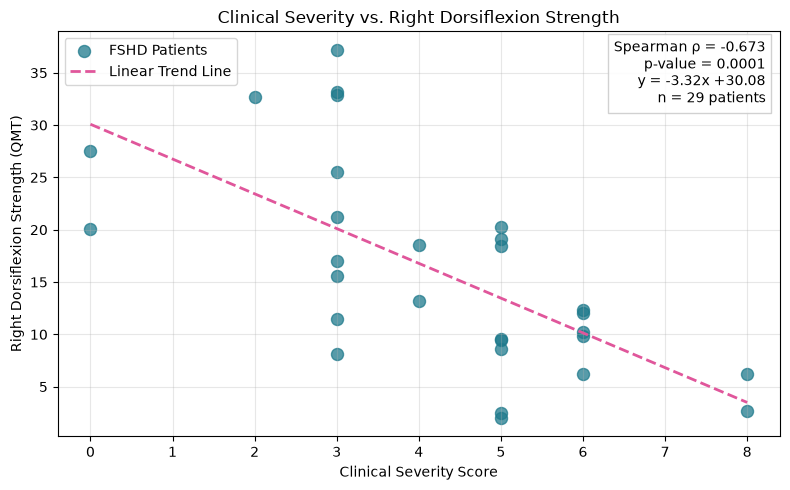

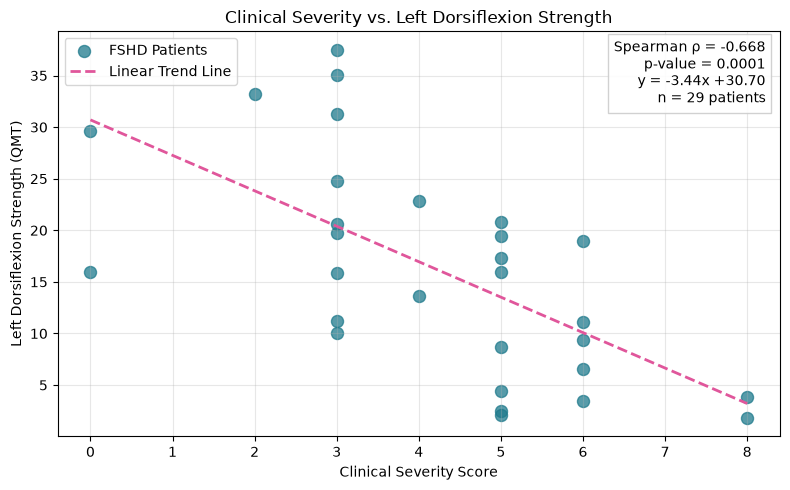

In [51]:
from scipy.stats import spearmanr

# Create separate scatterplots for right and left dorsiflexion
for name, data, column in [
    ("Right", right_df, "Right Dorsiflexion"),
    ("Left", left_df, "Left Dorsiflexion")
]:
    x = data["Clinical Severity"]
    y = data[column]

    # Calculate Spearman correlation and p-value
    correlation, p_value = spearmanr(x, y)

    # Calculate linear trend line equation
    slope, intercept = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = slope * x_line + intercept

    plt.figure(figsize=(8, 5))

    # Plot patient measurements
    plt.scatter(
        x, y,
        color="#1f7a8c",
        s=75,
        alpha=0.75,
        label="FSHD Patients"
    )

    # Plot linear trend line
    plt.plot(
        x_line, y_line,
        color="#e0569b",
        linestyle="--",
        linewidth=2,
        label="Linear Trend Line"
    )

    # Add statistics and equation to the graph
    stats_text = (
        f"Spearman ρ = {correlation:.3f}\n"
        f"p-value = {p_value:.4f}\n"
        f"y = {slope:.2f}x {intercept:+.2f}\n"
        f"n = {len(data)} patients"
    )

    plt.text(
        0.98, 0.98,
        stats_text,
        transform=plt.gca().transAxes,
        fontsize=10,
        verticalalignment="top",
        horizontalalignment="right",
        bbox=dict(
            facecolor="white",
            edgecolor="#cccccc",
            alpha=0.9
        )
    )

    plt.title(f"Clinical Severity vs. {name} Dorsiflexion Strength")
    plt.xlabel("Clinical Severity Score")
    plt.ylabel(f"{name} Dorsiflexion Strength (QMT)")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [52]:
from scipy.stats import spearmanr

# Calculate correlations separately for each leg
for name, data, column in [
    ("Right", right_df, "Right Dorsiflexion"),
    ("Left", left_df, "Left Dorsiflexion")
]:
    correlation, p_value = spearmanr(
        data["Clinical Severity"],
        data[column]
    )

    print(f"{name} Dorsiflexion:")
    print(f"  Number of patients: {len(data)}")
    print(f"  Spearman correlation: {correlation:.3f}")
    print(f"  P-value: {p_value:.4f}")
    print()

Right Dorsiflexion:
  Number of patients: 29
  Spearman correlation: -0.673
  P-value: 0.0001

Left Dorsiflexion:
  Number of patients: 29
  Spearman correlation: -0.668
  P-value: 0.0001



Based on the results, the clinical severity vs right dorsiflexion graph and the clinical severity vs left dorsiflextion graph both present a negative correlation, as expected. Both graphs have a p-value of 0.0001, which means there is a highly significant correlation between the variables in each graph. This supports the statement that a patient with a higher clinical severity score tends to have lower dorsiflexion strength. It is important to note that an association does not directly mean a causation. The purpose of this analysis was to provide evidence of an association, not a causation. 

The two different graphs show very similar results, and the same P-value, but the left dorsiflexion graph has a slightly more negative slope.

### Research Question 2: Do clinical severity scores and dorsiflexion strength change over time? ###

This analysis will be exploring whether the clinical severity scores and dorsiflexion strengths change over time. Instead of using Patients' measurements from one visit and comparing their relationship with the Spearman's correlation, we will be using a paired statistic test with patient data from all three visits. 

The graphs will be using actual measurements instead of interpolated values, to ensure as much accuracy as possible.

The code below finds the number of patients that have an appropriate amount of measurements to be included in the analysis.

In [53]:
from scipy.stats import friedmanchisquare

# Measurement columns for each outcome
measurements = {
    "Clinical Severity Score": [
        "clinical_severity_score_baseline",
        "clinical_severity_score_y1",
        "clinical_severity_score_y2"
    ],
    "Right Dorsiflexion Strength": [
        "dorsiflexion_qmt_R_baseline",
        "dorsiflexion_qmt_R_y1",
        "dorsiflexion_qmt_R_y2"
    ],
    "Left Dorsiflexion Strength": [
        "dorsiflexion_qmt_L_baseline",
        "dorsiflexion_qmt_L_y1",
        "dorsiflexion_qmt_L_y2"
    ]
}

visits = ["Baseline", "Year 1", "Year 2"]

# Keep complete cases separately for each outcome
longitudinal_data = {}

for name, columns in measurements.items():
    data = df[columns].dropna().copy()
    longitudinal_data[name] = data

    print(f"{name}: {len(data)} patients with all three measurements")

Clinical Severity Score: 26 patients with all three measurements
Right Dorsiflexion Strength: 22 patients with all three measurements
Left Dorsiflexion Strength: 22 patients with all three measurements


The following code uses a nonparametric test for repeated measurements, called the Freidman test, to examine if there is change in the three separate variables over time. It will take the mean clinical severity, right dorsiflexion strenght, and left dorsiflection strength of each patient and plot each of the three variables over time. 

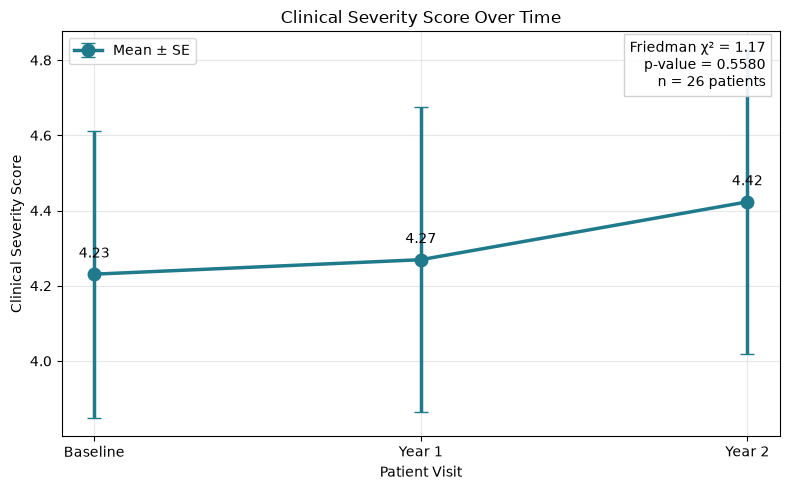

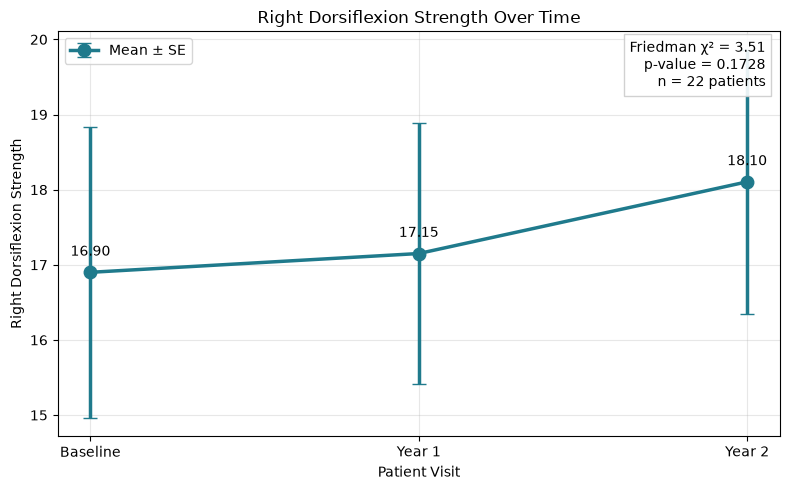

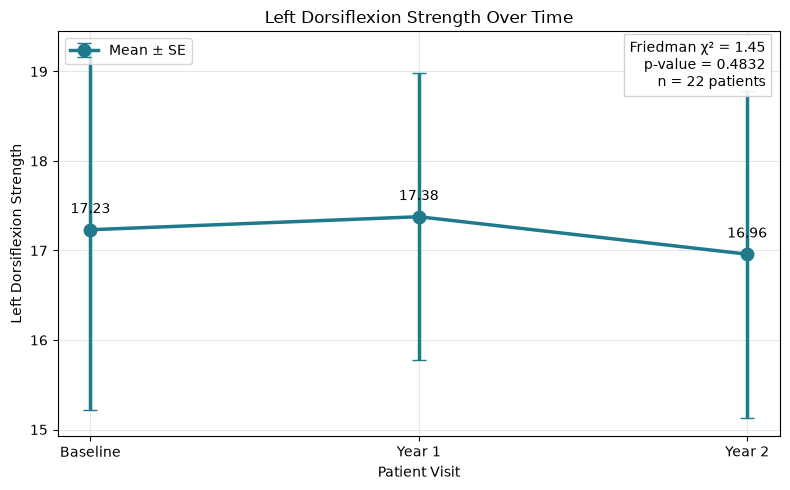

In [54]:
# Colors
TEAL = "#1f7a8c"
PINK = "#e0569b"

for name, data in longitudinal_data.items():

    # Calculate descriptive statistics
    means = data.mean().to_numpy()
    sem = data.sem().to_numpy()

    # Friedman test across three repeated visits
    statistic, p_value = friedmanchisquare(
        data.iloc[:, 0],
        data.iloc[:, 1],
        data.iloc[:, 2]
    )

    x = np.arange(3)

    plt.figure(figsize=(8, 5))

    # Plot mean values with standard error bars
    plt.errorbar(
        x, means,
        yerr=sem,
        color=TEAL,
        marker="o",
        markersize=9,
        linewidth=2.5,
        capsize=5,
        label="Mean ± SE"
    )

    # Label mean values
    for i, value in enumerate(means):
        plt.annotate(
            f"{value:.2f}",
            (i, value),
            xytext=(0, 12),
            textcoords="offset points",
            ha="center"
        )

    # Statistics box
    stats_text = (
        f"Friedman χ² = {statistic:.2f}\n"
        f"p-value = {p_value:.4f}\n"
        f"n = {len(data)} patients"
    )

    plt.text(
        0.98, 0.98,
        stats_text,
        transform=plt.gca().transAxes,
        fontsize=10,
        va="top",
        ha="right",
        bbox=dict(
            facecolor="white",
            edgecolor="#cccccc",
            alpha=0.9
        )
    )

    plt.xticks(x, visits)
    plt.title(f"{name} Over Time")
    plt.xlabel("Patient Visit")
    plt.ylabel(name)
    plt.grid(True, alpha=0.3)
    plt.legend(loc="upper left")
    plt.tight_layout()
    plt.show()

Starting with clinical severity over time, a visual increase in score can be observed, but the p-value is above 0.05, which deems the data insignificantly correlated. 

The right dorsiflexion over time also displays a visual increase between the baseline and Year 1 visits and the Year 1 and Year 2 visits. However, the p value is also above 0.05, which means there is no sufficient evidence of statistical significance.

Finally, the left dorsiflexion graph shows an increase in strength between the baseline and Year 1 visits, but a decrease between the Year 1 and Year 2 visits. This graph, like the ones before, does not have a significant p value. 

### Research Question 3: Is there a significant difference in left versus right dorsiflexion strength over time? ###

In this analysis, we will be comparing right dorsiflexion strenght vs left dorsiflexion strenght in patients over time. FSHD tends to present asymmetrically, so we are exploring whether there is any statistical significance behind that.

The statistical analysis being performed is the Wilcoxon signed-rank test, which determines whether there is a significant difference between two related measurements. It works by calculating the difference betwen the two values and ranking the differences to determine whether they differ symmetrically. A p-value less than 0.05 means there is a significant difference between the left and right dorsiflexion strength. 

In [55]:
from scipy.stats import wilcoxon

leg_columns = {
    "Baseline": (
        "dorsiflexion_qmt_R_baseline",
        "dorsiflexion_qmt_L_baseline"
    ),
    "Year 1": (
        "dorsiflexion_qmt_R_y1",
        "dorsiflexion_qmt_L_y1"
    ),
    "Year 2": (
        "dorsiflexion_qmt_R_y2",
        "dorsiflexion_qmt_L_y2"
    )
}

leg_results = []

for visit, (right_col, left_col) in leg_columns.items():

    # Use only patients with both legs measured at this visit
    paired = df[[right_col, left_col]].dropna()

    # Compare left and right strength
    statistic, p_value = wilcoxon(
        paired[right_col],
        paired[left_col],
        zero_method="wilcox"
    )

    leg_results.append({
        "Visit": visit,
        "n": len(paired),
        "Right Mean": paired[right_col].mean(),
        "Left Mean": paired[left_col].mean(),
        "Mean Difference (R-L)": (
            paired[right_col] - paired[left_col]
        ).mean(),
        "p-value": p_value
    })

leg_results_df = pd.DataFrame(leg_results)

display(leg_results_df.round(3))

,Visit,n,Right Mean,Left Mean,Mean Difference (R-L),p-value
0,Baseline,29,15.986,16.128,-0.141,0.948
1,Year 1,26,17.438,17.615,-0.177,0.751
2,Year 2,25,17.044,15.964,1.080,0.426


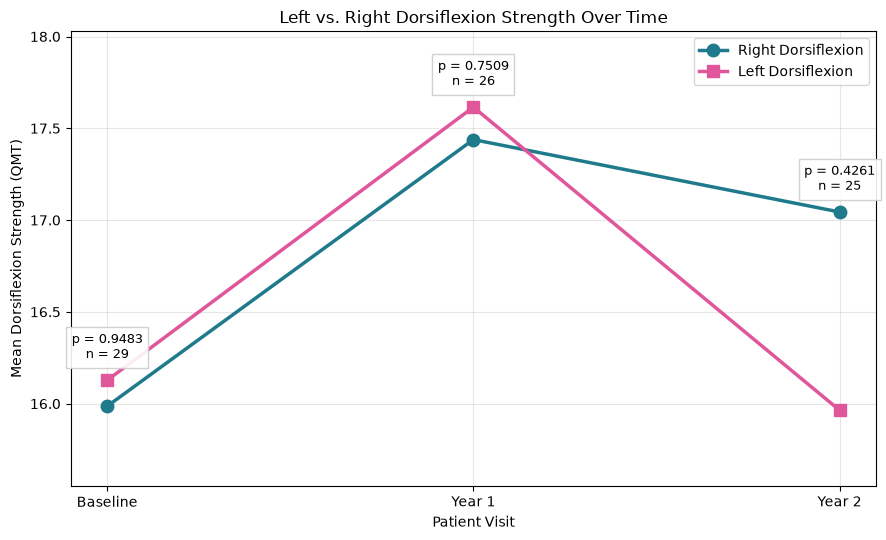

In [56]:
# Extract values for graphing
x = np.arange(3)

right_means = leg_results_df["Right Mean"].to_numpy()
left_means = leg_results_df["Left Mean"].to_numpy()

plt.figure(figsize=(9, 5.5))

# Right leg
plt.plot(
    x, right_means,
    color="#1f7a8c",
    marker="o",
    markersize=9,
    linewidth=2.5,
    label="Right Dorsiflexion"
)

# Left leg
plt.plot(
    x, left_means,
    color="#e0569b",
    marker="s",
    markersize=9,
    linewidth=2.5,
    label="Left Dorsiflexion"
)

# Display p-values for each visit
for i, row in leg_results_df.iterrows():
    upper = max(row["Right Mean"], row["Left Mean"])

    plt.annotate(
        f"p = {row['p-value']:.4f}\nn = {row['n']}",
        (i, upper),
        xytext=(0, 16),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        bbox=dict(
            facecolor="white",
            edgecolor="#cccccc",
            alpha=0.9
        )
    )

plt.xticks(x, visits)
plt.title("Left vs. Right Dorsiflexion Strength Over Time")
plt.xlabel("Patient Visit")
plt.ylabel("Mean Dorsiflexion Strength (QMT)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.margins(y=0.25)
plt.tight_layout()
plt.show()

The graph shows no statistically significant difference between the right and left dorsiflexion strengths, as provided by the p-values. From the baseline visit to visit 1, there is an increase in dorsiflexion strength. Left dorsiflexion is consistantly above right dorsiflexion strength. Both left and right dorsiflexion strengths decrease after Year 1 until Year 2. It can be observed that left dorsiflexion strenght has a much steeper decrease than right dorsiflexion. 

## Conclusions:

Explain what your analysis suggests about measuring FSHD progression.

Discuss:

- Which MRI, biomarker, or functional measures changed most consistently
- Which measures appeared most sensitive to differences across muscle locations or visits
- Whether the measures could be useful as biomarkers or exploratory clinical-trial endpoints
- What additional evidence would be needed before using them to evaluate treatment effectiveness
- Potential ethical implications of selecting one measure over another, including patient relevance, accessibility, and the risk of overlooking meaningful changes in function


"If clinical severity scores and dorsiflexion strength change differently, we need to investigate which measurement detects meaningful disease progression more consistently across patients, rather than assuming both will worsen every year.

Also, remember that interpolation estimates values between observations. It cannot tell us whether an apparent improvement reflects genuine recovery or measurement variability."

## Limitations and Future Work:

Describe the limitations of your project, including limitations of the sample size, available visits, MRI measurements, segmentation, biomarkers, functional measures, and analysis methods.

"Notice that the clinical severity score is estimated as 6.82, even though clinical scores may be recorded as whole numbers. That's okay for a mathematical interpolation estimate, but it is not an actual observed clinical score."

If you had more time or additional data, explain how you would improve the analysis. Examples include analyzing more participants, adding more timepoints, improving segmentation, comparing additional muscles, validating the MRI measure against functional outcomes, or testing whether the measure is sensitive to treatment response.

## AI Usage Statement:

We used ChatGPT to help write the code to split the histogram into two seperate histograms, one for the whole MRI image and one for solely the TA muscle. We used ChatGPT to reword some sentences to ensure grammar was correct. 

## GitHub Repository Link:

https://github.com/mabouassi2288/Module-2.git


## References:

<p style="text-indent: -1.5em; margin-left: 1.5em;">
    <b>Brun, B. N., Camarta, N., Johnson, N., Schoser, B., Statland, J., & Voermans, N. C. (2026). Overview of facioscapulohumeral dystrophy clinical features and diagnostic pathway. Neuromuscular Disorders, 61, 106389. https://doi.org/10.1016/j.nmd.2026.106389</b> 

 <p style="text-indent: -1.5em; margin-left: 1.5em;">
    <b>Diseases - FSHD - signs & symptoms. (2015, December 18). Muscular Dystrophy Association. https://www.mda.org/disease/facioscapulohumeral-muscular-dystrophy/signs-and-symptoms</b>    

 <p style="text-indent: -1.5em; margin-left: 1.5em;">
    <b>Facts and statistics FSHD - Wellstone Program - UMass Medical School - Worcester. (2014, March 4). University of Massachusetts Medical School. https://www.umassmed.edu/wellstone/overview/fshdfacts/</b>   

 <p style="text-indent: -1.5em; margin-left: 1.5em;">
    <b>FSHD (facioscapulohumeral muscular dystrophy). (2023, December 6). Cleveland Clinic. https://my.clevelandclinic.org/health/diseases/facioscapulohumeral-muscular-dystrophy-fshd</b>   

 <p style="text-indent: -1.5em; margin-left: 1.5em;">
    <b>Muscular Dystrophy Association. (2015, December 18). Facioscapulohumeral muscular dystrophy (FSH, FSHD) - medical management | muscular dystrophy association. Muscular Dystrophy Association. https://www.mda.org/disease/facioscapulohumeral-muscular-dystrophy/medical-management</b>   

 <p style="text-indent: -1.5em; margin-left: 1.5em;">
    <b>Preston, M. K., & Wang, L. H. (2025, July 10). Facioscapulohumeral muscular dystrophy. University of Washington, Seattle. Ncbibooks. https://www.ncbi.nlm.nih.gov/books/NBK1443/</b>   
   
 <p style="text-indent: -1.5em; margin-left: 1.5em;">
    <b>Wong, C. J., Friedman, S. D., Snider, L., Bennett, S. R., Jones, T. I., Jones, P. L., Shaw, D. W. W., Blemker, S. S., Riem, L., DuCharme, O., Lemmers, R. J. F. L., van der Maarel, S. M., Wang, L. H., Tawil, R., Statland, J. M., & Tapscott, S. J. (2024). Regional and bilateral MRI and gene signatures in facioscapulohumeral dystrophy: implications for clinical trial design and mechanisms of disease progression. Human molecular genetics, 33(8), 698–708. https://doi.org/10.1093/hmg/ddae007 /b>   

## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*